In [11]:
import matplotlib.pyplot as plt
import contextily as ctx
import numpy as np
from pyproj import Transformer
import requests
from PIL import Image
from io import BytesIO


files = [
    "../../Data/DGPS data/onyx_101726.csv",
    "../../Data/DGPS data/onyx_ert_92726.csv",
    "../../Data/DGPS data/onyx_senior_design_092625.csv"
]


High-resolution USGS imagery loaded!


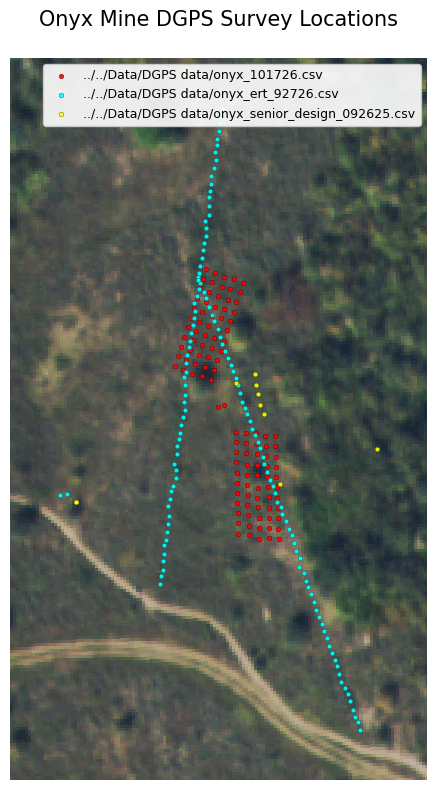

In [12]:

# =====================================
# SETTINGS - CHANGE THESE
# =====================================

FIG_WIDTH = 12       # Printed width in inches
FIG_HEIGHT = 8        # Printed height in inches
DPI = 300             # Print resolution
POINT_SIZE = 12       # Size of DGPS points
MAP_PADDING = 0.08    # Space around survey points

colors = ["red", "cyan", "yellow"]

legend_names = [
    "EM31 & Gravity surveys",
    "ERT surveys",
    "Mine tunnel 1 opening"
]
# =====================================
# CONVERT GPS TO MAP COORDINATES
# =====================================

# WGS84 latitude/longitude -> Web Mercator
transformer = Transformer.from_crs(
    "EPSG:4326",
    "EPSG:3857",
    always_xy=True
)

fig, ax = plt.subplots(
    figsize=(FIG_WIDTH, FIG_HEIGHT)
)

all_x = []
all_y = []

for (filename, df), color in zip(surveys, colors):

    x, y = transformer.transform(
        df["Longitude"].to_numpy(),
        df["Latitude"].to_numpy()
    )

    all_x.extend(x)
    all_y.extend(y)

    ax.scatter(
        x, y,
        s=POINT_SIZE,
        c=color,
        edgecolors="black",
        linewidths=0.2,
        alpha=0.9,
        label=filename,
        zorder=5
    )

# =====================================
# SET MAP EXTENT
# =====================================

xmin, xmax = min(all_x), max(all_x)
ymin, ymax = min(all_y), max(all_y)

span = max(xmax - xmin, ymax - ymin)
padding = max(span * MAP_PADDING, 5)

ax.set_xlim(xmin - padding, xmax + padding)
ax.set_ylim(ymin - padding, ymax + padding)


# =====================================
# HIGH-RESOLUTION USGS AERIAL IMAGERY
# =====================================

# Get current map boundaries
xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()

# Request a high-resolution image
width_px = 3200
height_px = round(
    width_px * (ymax - ymin) / (xmax - xmin)
)

# USGS service supports images up to 4000 px per side
scale = min(1, 4000 / max(width_px, height_px))
width_px = max(1, round(width_px * scale))
height_px = max(1, round(height_px * scale))

url = (
    "https://imagery.nationalmap.gov/arcgis/rest/"
    "services/USGSNAIPImagery/ImageServer/exportImage"
)

params = {
    "bbox": f"{xmin},{ymin},{xmax},{ymax}",
    "bboxSR": 3857,
    "imageSR": 3857,
    "size": f"{width_px},{height_px}",
    "format": "jpg",
    "f": "image"
}

response = requests.get(url, params=params, timeout=90)
response.raise_for_status()

image = Image.open(BytesIO(response.content)).convert("RGB")

ax.imshow(
    image,
    extent=[xmin, xmax, ymin, ymax],
    origin="upper",
    zorder=0,
    interpolation="nearest"
)

print("High-resolution USGS imagery loaded!")

# =====================================
# FORMATTING
# =====================================

ax.set_aspect("equal")
ax.set_axis_off()

ax.legend(
    loc="upper right",
    fontsize=9,
    framealpha=0.9
)

ax.set_title(
    "Onyx Mine DGPS Survey Locations",
    fontsize=15,
    pad=12
)

plt.tight_layout()

# =====================================
# SAVE FOR PRINTING
# =====================================


plt.show()


In [13]:
# Find the Senior Design dataset
senior_name, senior_df = next(
    (name, df) for name, df in surveys
    if "senior" in name.lower()
)

print(f"File: {senior_name}")
print(f"Total points: {len(senior_df)}")

# Display point indices and coordinates
display(
    senior_df[["Latitude", "Longitude"]]
    .rename_axis("Point ID")
    .reset_index()
)

File: ../../Data/DGPS data/onyx_senior_design_092625.csv
Total points: 10


,Point ID,Latitude,Longitude
0,0,40.478769,-106.835987
1,1,40.478769,-106.835987
2,2,40.478863,-106.835294
3,3,40.478977,-106.835619
4,4,40.478993,-106.835575
5,5,40.478975,-106.835572
6,6,40.478958,-106.835568
7,7,40.478940,-106.835562
8,8,40.478924,-106.835555
9,9,40.478802,-106.835517
